In [12]:
import numpy as np 
import matplotlib.pyplot as plt 
from idmlm import *
from sklearn.svm import SVC

## Support Vector Machines 

- Some Problems cannot be seperated easily due to the nature of the data as we have below. 

- The advantage of SVM is that we can by pass this problem via the Kernal trick 



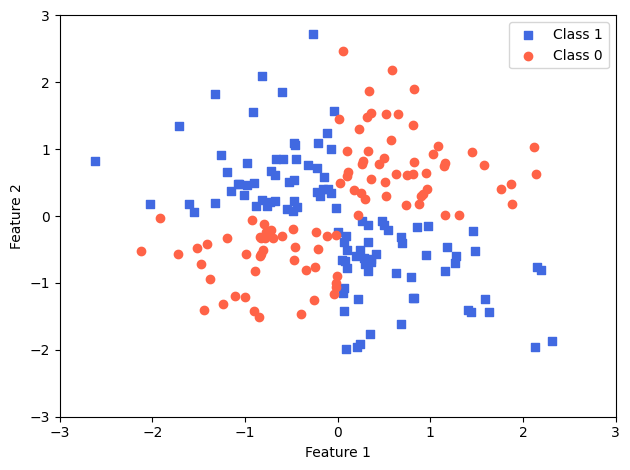

In [13]:
np.random.seed(42)

x_xor = np.random.randn(200, 2 )
y_xor = np.logical_xor(x_xor[:,0] > 0 , x_xor[: , 1] > 0)

y_xor = np.where(y_xor , 1 , 0)
plt.scatter(x_xor[y_xor == 1 , 0] , x_xor[y_xor == 1,1],
            c = "royalblue" , marker = "s" , label = "Class 1")

plt.scatter(x_xor[y_xor == 0 , 0] , x_xor[y_xor == 0,1],
            c = "tomato" , marker = "o" , label = "Class 0")

plt.xlim([-3, 3])
plt.ylim([-3, 3])
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

- "The basic idea behind kernel methods for dealing with such linearly inseparable data is to create nonlinear combinations of the original features to project them onto a higher-dimensional space via a mapping function, 𝜙𝜙 , where the data becomes linearly separable."

- 𝜙
 𝜙(𝑥𝑥1,𝑥𝑥2) = (𝑧𝑧1,𝑧𝑧2,𝑧𝑧3) = (𝑥𝑥1,𝑥𝑥2,𝑥𝑥1
 2 +𝑥𝑥2



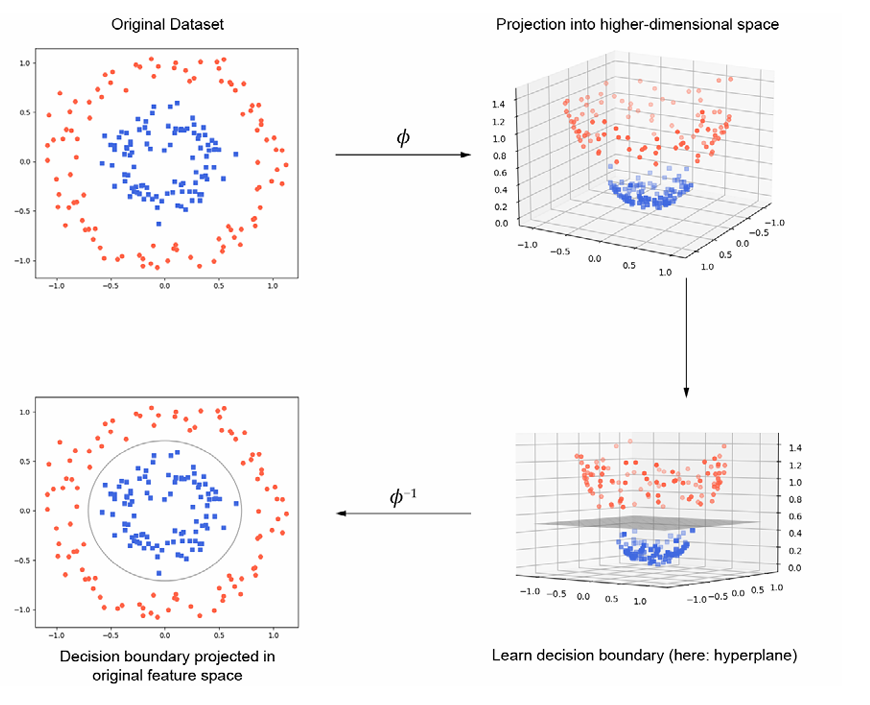

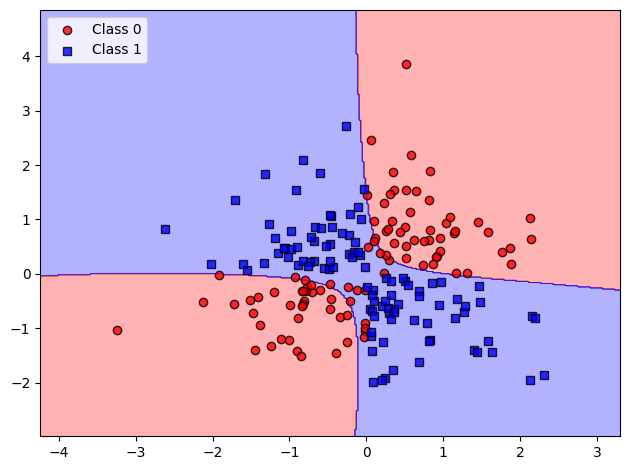

In [15]:
svm = SVC(kernel = "rbf" , random_state = 1 , gamma = 0.10 , C = 10.0)

svm.fit(x_xor , y_xor)

plot_decision_regions(x_xor , y_xor , classifier = svm)

plt.legend(loc = "upper left")

plt.tight_layout()

plt.show()

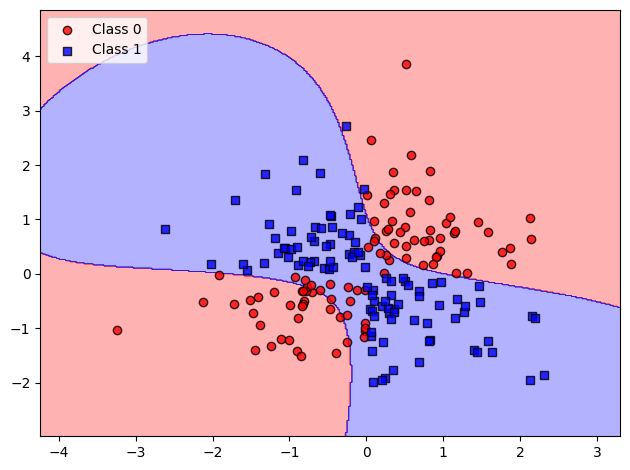

In [16]:
svm = SVC(kernel = "rbf" , random_state = 1 , gamma = 0.2 , C = 1.0)

svm.fit(x_xor , y_xor)

plot_decision_regions(x_xor , y_xor , classifier = svm)

plt.legend(loc = "upper left")

plt.tight_layout()

plt.show()

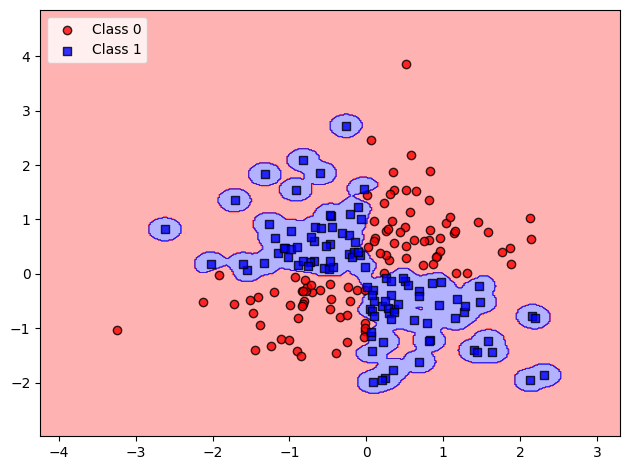

In [17]:
svm = SVC(kernel = "rbf" , random_state = 1 , gamma = 100 , C = 1.0)

svm.fit(x_xor , y_xor)

plot_decision_regions(x_xor , y_xor , classifier = svm)

plt.legend(loc = "upper left")

plt.tight_layout()

plt.show()

# Decision tree learning

- This is an attractive classifier if we are interested in getting interpretation from our model
 
- it is simple and easy 

- we ask a series of questions of the data and split based on this. 



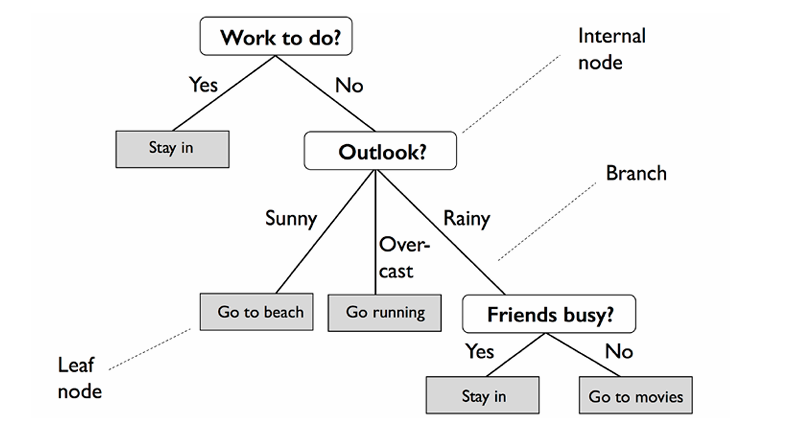

### Maximizing IG – getting the most bang for your buck 

- Goal: Split the nodes at the most informative features at each split.

- The information gain is simply the difference between the impurity of the parent node and the sum of the child node impurities

- hence we are splitting on the child node that reduces the impurity of the parents the most.

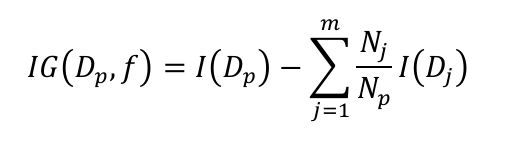

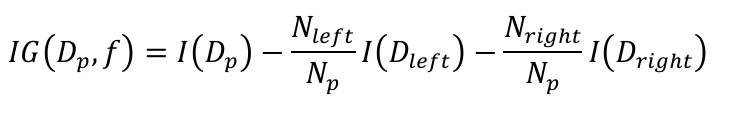

##### Impurity measures 

- Classification error 

- Entropy 

- Gini Impurity :  The Gini impurity can be understood as a criterion to minimize the probability of misclassification:

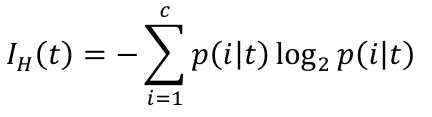

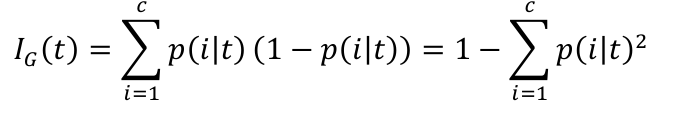

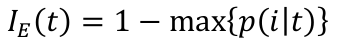

- The entropy is therefore 0 if all examples at a node belong to the same class, and the entropy is maximal if we have a uniform class distribution.

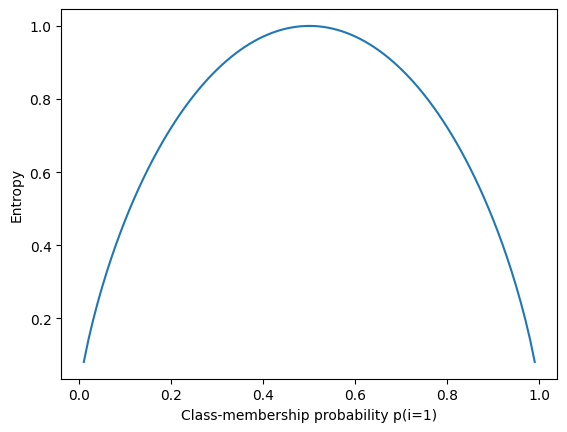

In [2]:
def entropy(p):
    return - p * np.log2(p) - (1 - p) * np.log2((1 - p))


x = np.arange(0.0, 1.0, 0.01)
ent = [entropy(p) if p != 0 else None for p in x]
plt.ylabel('Entropy')
plt.xlabel('Class-membership probability p(i=1)')
plt.plot(x, ent)
plt.show()

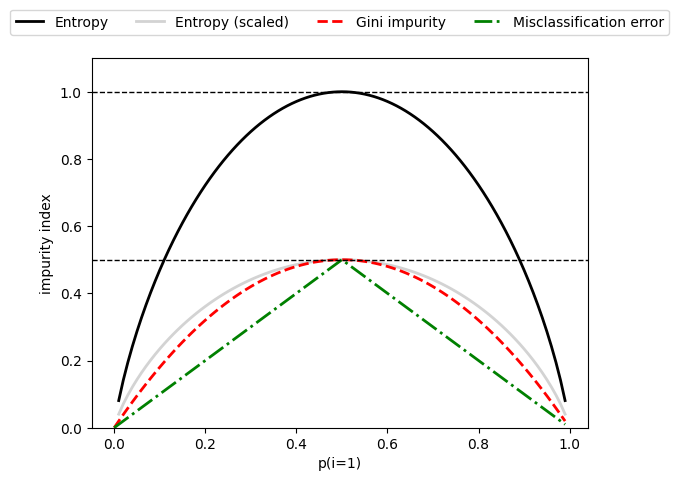

In [5]:
def gini(p): 
    return p*(1 - p) + (1 - p)*(1 - (1-p))
def entropy(p):
      
    return - p*np.log2(p) - (1 - p)*np.log2((1 - p))
def error(p):
     
    return 1 - np.max([p, 1 - p])
x = np.arange(0.0, 1.0, 0.01)
ent = [entropy(p) if p != 0 else None for p in x]
sc_ent = [e*0.5 if e else None for e in ent]
err = [error(i) for i in x]
fig = plt.figure()
ax = plt.subplot(111)
for i, lab, ls, c, in zip([ent, sc_ent, gini(x), err],
                         ['Entropy', 'Entropy (scaled)',
                          'Gini impurity',
                          'Misclassification error'],
                         ['-', '-', '--', '-.'],
                         ['black', 'lightgray',
                          'red', 'green', 'cyan']):
    line = ax.plot(x, i, label=lab,
                   linestyle=ls, lw=2, color=c)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15),
          ncol=5, fancybox=True, shadow=False)
ax.axhline(y=0.5, linewidth=1, color='k', linestyle='--')
ax.axhline(y=1.0, linewidth=1, color='k', linestyle='--')
plt.ylim([0, 1.1])
plt.xlabel('p(i=1)')
plt.ylabel('impurity index')
plt.show()

#####  Building a decision tree 


In [18]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

In [19]:
# Load iris dataset
iris = datasets.load_iris()
X = iris.data[:, [2, 3]]  # Use only petal length and petal width
y = iris.target

# Step 1: Split the data FIRST
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                     random_state=1, stratify=y)

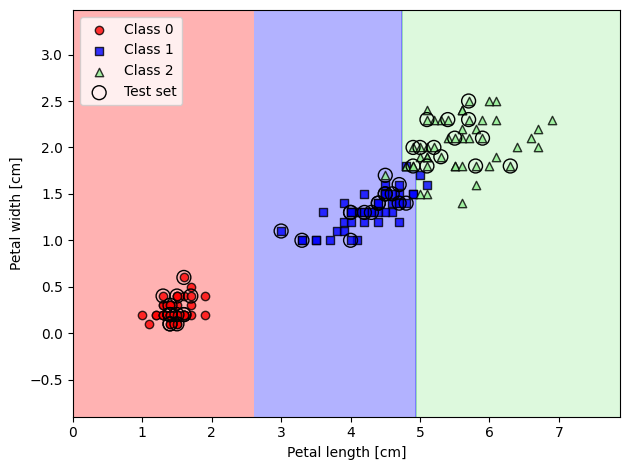

In [21]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(criterion = "gini" , max_depth= 4 , random_state=42)

tree_model.fit(X_train , y_train)

X_combined = np.vstack((X_train , X_test))
y_combined = np.hstack((y_train , y_test))

plot_decision_regions(X_combined , y_combined , classifier=tree_model , test_idx= range(105 , 150))

plt.xlabel('Petal length [cm]')
plt.ylabel('Petal width [cm]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

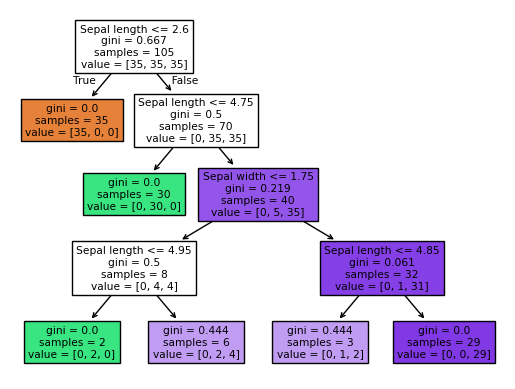

In [22]:
from sklearn import tree 

feature_names = ['Sepal length', 'Sepal width',  'Petal length', 'Petal width']

tree.plot_tree(tree_model , feature_names= feature_names , filled =True)

plt.show()

#### Exercise 

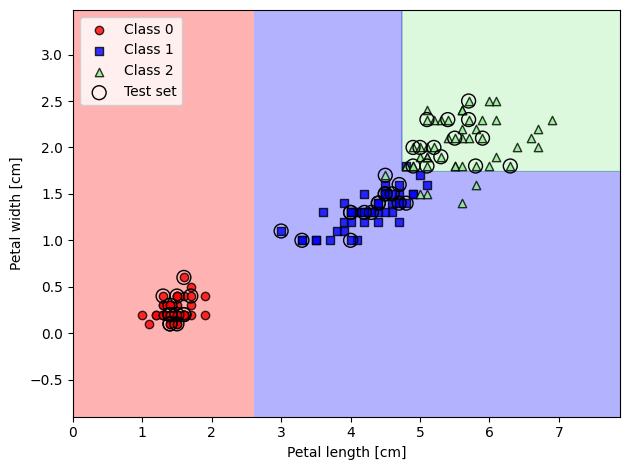

In [24]:
tree_model = DecisionTreeClassifier(criterion = "gini" , max_depth= 3 , random_state=42)

tree_model.fit(X_train , y_train)

X_combined = np.vstack((X_train , X_test))
y_combined = np.hstack((y_train , y_test))

plot_decision_regions(X_combined , y_combined , classifier=tree_model , test_idx= range(105 , 150))

plt.xlabel('Petal length [cm]')
plt.ylabel('Petal width [cm]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

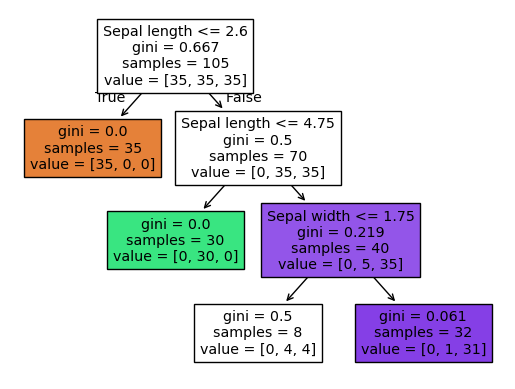

In [25]:
feature_names = ['Sepal length', 'Sepal width',  'Petal length', 'Petal width']

tree.plot_tree(tree_model , feature_names= feature_names , filled =True)

plt.show()

#### Combining multiple decision trees via random forests

- A random forest can be considered as an ensemble of decision trees.

   1. Draw a random bootstrap sample of size n (randomly choose n examples from the training dataset with replacement).

   2. Grow a decision tree from the bootstrap sample. At each node:
      a. Randomly select d features without replacement.
      b. Split the node using the feature that provides the best split according to the objective function, for instance, maximizing the information gain.

   3. Repeat steps 1-2 k times.
   
   4. Aggregate the prediction by each tree to assign the class label by majority vote.



 - advantage of random forests is that we don’t have to worry so much about choosing good hyperparameter values

 -  The only parameter that we 
   need to care about in practice is the number of trees, k, (step 3) that we choose for the random forest. 
   Typically, the larger the number of trees, the better the performance of the random forest classifier 
   at the expense of an increased computational cost.

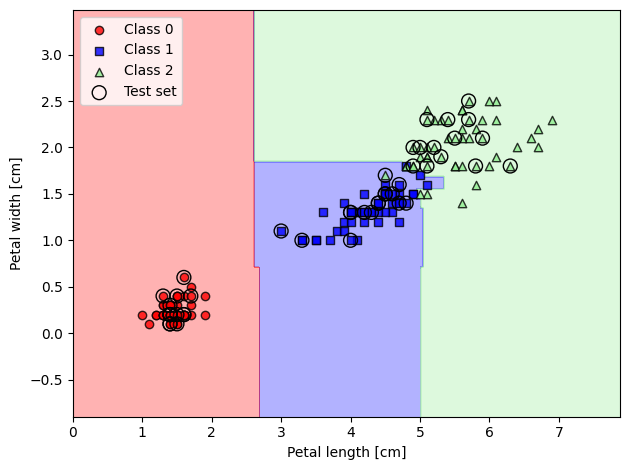

In [33]:
from sklearn.ensemble import RandomForestClassifier
forest = RandomForestClassifier(n_estimators=25,
                                 random_state=1,
                                 n_jobs=16)
forest.fit(X_train, y_train)
plot_decision_regions(X_combined, y_combined,classifier=forest, test_idx=range(105,150))
plt.xlabel('Petal length [cm]')
plt.ylabel('Petal width [cm]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

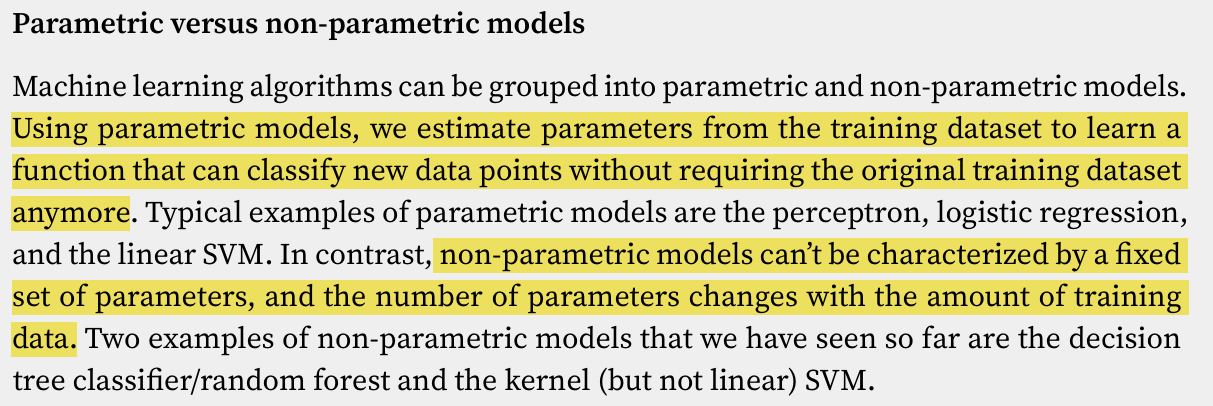

#### K-nearest neighbors – a lazy learning algorithm

- it doesn’t learn a discriminative function from the training data but memorizes the training 
    dataset instead.

-  The main advantage of such a memory-based approach is that the classifier immediately 
    adapts as we collect new training data

- Still being Implemented 

-  The right choice of k is crucial to finding a good balance between overfitting and underfitting

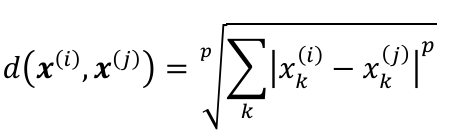

In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [60]:
# Step 1: Load iris dataset

iris = datasets.load_iris()
X = iris.data[:, [2, 3]]  # Use only petal length and petal width
y_combined = iris.target

# Step 2: Standardize the features
sc = StandardScaler()
sc.fit(X)
X_combined_std = sc.transform(X)

# Step 3: Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined_std, 
    y_combined, 
    test_size=0.2,  # 20% for testing
    random_state=42,  # For reproducibility
    stratify=y_combined  # Maintain class distribution
)
# Step 4: Combine train and test sets back together
X_recombined = np.vstack([X_train, X_test])
y_recombined = np.hstack([y_train, y_test])


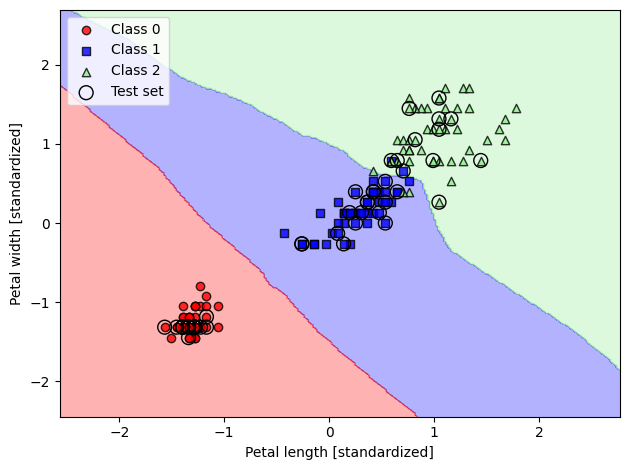

In [61]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5, p=2,
                             metric='minkowski')
knn.fit(X_train, y_train)
plot_decision_regions(X_recombined, y_recombined,
                       classifier=knn, test_idx=range(105,150))
plt.xlabel('Petal length [standardized]')
plt.ylabel('Petal width [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()